In [1]:
import pathlib

import numpy as np
import pandas as pd
import scipy as sp
from matplotlib import pyplot as plt

import el_hd_plasticity.two_photon as nmp

plt.rcParams["pdf.fonttype"] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline


In [4]:
basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/EPG_jGCaMP7f_OctB1RRNAi')
figdir  = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EPG_jGCaMP7f_OctB1RRNAi')

sess_manager = nmp.loading.SessionManager(
    basedir=basedir, 
    figfolder=figdir,
    folder_cols=('condition',), 
    basedir_col='basedir', 
    id_cols=['condition',])
sess_manager.filter_rows((sess_manager.sess_df['condition']=='control') * (sess_manager.sess_df['usable']==1))

In [5]:
sess_manager.sess_df.head()

,date,fly,session,closed_loop,rnai,condition,usable,fictrac_dat_file,notes,fly_id
0,06_01_2025,fly1,closed_loop-000,1,0,control,1,fictrac-20250106_102710.dat,NaN,06_01_2025_fly1_condition_control
1,06_01_2025,fly1,dark-001,0,0,control,1,fictrac-20250106_102710.dat,NaN,06_01_2025_fly1_condition_control
2,06_01_2025,fly1,closed_loop-002,2,0,control,1,fictrac-20250106_102710.dat,NaN,06_01_2025_fly1_condition_control
3,06_01_2025,fly2,closed_loop-000,1,0,control,1,fictrac-20250106_112036.dat,NaN,06_01_2025_fly2_condition_control
4,06_01_2025,fly2,dark-001,0,0,control,1,fictrac-20250106_112036.dat,NaN,06_01_2025_fly2_condition_control


In [6]:
offset_stats = nmp.stats.offset_stats(sess_manager, meta_cols=('fly_id', 'condition', 'closed_loop'))

## plot PVA mag

In [7]:
offset_stats_unique = nmp.stats.offset_stats_unique(offset_stats, group_col='condition', dark_col=None)

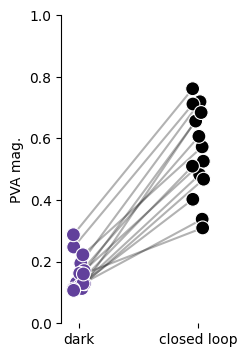

In [8]:
import seaborn as sns

df = offset_stats_unique.copy()

rng = np.random.default_rng(0)
jitter = dict(zip(df['fly_id'].unique(), rng.uniform(-.05, .05, df['fly_id'].nunique()),strict=True))
df['x'] = ( df['closed_loop']) + df['fly_id'].map(jitter)   # dark=0, stripe=1

fig, ax = plt.subplots(figsize=[2, 4])
_ = sns.lineplot(data=df, x='x', y='offset_mag', units='fly_id', estimator=None,
             color='black', zorder=-10, ax=ax, alpha=.3)
_ = sns.scatterplot(data=df, x='x', y='offset_mag', hue='closed_loop',
                palette={0: plt.cm.Purples(.8), 1: 'black'}, s=100, legend=False, ax=ax)

ax.set_xticks([0,1], labels=('dark', 'closed loop'))
ax.set_ylabel('PVA mag.')
ax.set_xlabel('')
ax.set_ylim([0,1.])
ax.set_yticks([0,.2,.4,.6,.8,1])
ax.set_xlim([-.15,1.15])

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

fig.savefig(sess_manager.fig_folder / "PVA_mag_dark_v_closed_loop.pdf")

In [9]:
wide = offset_stats_unique.pivot(index='fly_id', columns='closed_loop', values='offset_mag').dropna()

W, p = sp.stats.wilcoxon(wide[0].astype(float), wide[1].astype(float))
print(f'offset mag dark vs closed loop: n={len(wide)}, W={W}, p={p}')



offset mag dark vs closed loop: n=14, W=0.0, p=0.0001220703125


## plot diff in pva angle

In [10]:
offset_mean_wide = offset_stats.pivot(index='fly_id', columns='closed_loop', values='offset_mean').dropna()

# for plotting, wrap axes
cl_1 = offset_mean_wide[1].to_numpy()
cl_2 = offset_mean_wide[2].to_numpy()
cl_2_expand = cl_2[:, np.newaxis] + np.array([2*np.pi, 0, -2*np.pi])[np.newaxis,:]

arg = np.argmin(np.abs(cl_2_expand-cl_1[:,np.newaxis]),axis=-1,keepdims=True)
cl_2_min = np.take_along_axis(cl_2_expand,arg)
offset_mean_wide[2]=cl_2_min


cl_offset_df = offset_mean_wide[[1, 2]].reset_index().melt(
    id_vars='fly_id',
    var_name='closed_loop',
    value_name='offset_mean')
    


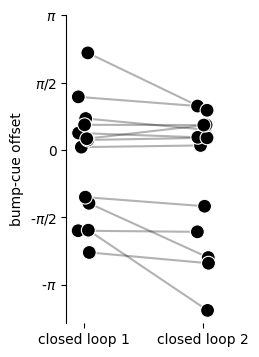

In [11]:
df = cl_offset_df.copy()

rng = np.random.default_rng(0)
jitter = dict(zip(df['fly_id'].unique(), rng.uniform(-.05, .05, df['fly_id'].nunique()),strict=True))
df['x'] = (-1 + df['closed_loop']) + df['fly_id'].map(jitter)   # dark=0, stripe=1

fig, ax = plt.subplots(figsize=[2, 4])
_ = sns.lineplot(data=df, x='x', y='offset_mean', units='fly_id', estimator=None,
             color='black', zorder=-10, ax=ax, alpha=.3)
_ = sns.scatterplot(data=df, x='x', y='offset_mean', hue='closed_loop',
                palette={1: 'black', 2: 'black'}, s=100, legend=False, ax=ax)

ax.set_xticks([0,1], labels=('closed loop 1', 'closed loop 2'))
ax.set_ylabel('bump-cue offset')
ax.set_xlabel('')

ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi], labels=[r"-$\pi$", r"-$\pi$/2", 0, r"$\pi$/2", r"$\pi$"])
ax.set_xlim([-.15,1.15])
 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

fig.savefig(sess_manager.fig_folder / "offset_cl1_v_cl2.pdf")

In [12]:
offset_mean_wide = offset_stats.pivot(index='fly_id', columns='closed_loop', values='offset_mean').dropna()
diff = np.abs(np.angle(np.exp(1j*(offset_mean_wide[1]-offset_mean_wide[2]))))

offset_mean_wide['diff']=diff
jitter = dict(zip(df['fly_id'].unique(), rng.uniform(-.02, .02, df['fly_id'].nunique()),strict=True))
offset_mean_wide['x'] = jitter



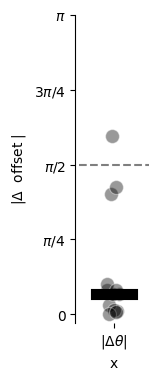

In [13]:
fig, ax = plt.subplots(figsize=[1,4])
_ = sns.scatterplot(data=offset_mean_wide, x='x', y='diff',
                color='black', s=100, legend=False, alpha=.4, ax=ax)


ax.plot([-.05,.05], np.median(diff)*np.ones([2,]), color='black', linewidth=8)
ax.plot([-.1,.1], [np.pi/2, np.pi/2], 'k--', alpha=.5, zorder=-1, label='chance')
# ax.plot([-.2, .2], np.pi/4*np.ones((2,)), 'r--', alpha=.5, zorder=-1, label='1 glomerulus')
# ax.legend()

_ = ax.set_yticks([0,np.pi/4,np.pi/2,3*np.pi/4, np.pi], labels=[0, r"$\pi$/4", r"$\pi$/2", r"$3\pi$/4", r"$\pi$"])
ax.set_xticks([.0], labels=[r'$| \Delta \theta |$'])
ax.set_ylabel(r'$| \Delta $  offset $|$')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

fig.savefig(sess_manager.fig_folder / "dOffset_cl1_v_cl2.pdf")

## Make attractor dynamics plots

In [14]:
dh_bins = np.linspace(-2, 2, num=20) # radians / sec
dh_bin_centers = (dh_bins[1:]+dh_bins[:-1])/2

dphi_stats = nmp.stats.dphi_stats(
    sess_manager,
    dh_bins,
    meta_cols=('fly_id', 'condition', 'closed_loop')
    )

In [15]:
dphi_stats.head()
dphi_stats = dphi_stats.loc[dphi_stats['closed_loop']!=1] # exclude first closed loop session
dphi_stats.loc[dphi_stats['closed_loop']>1, 'closed_loop'] = 1 #


In [ ]:
dphi_grouped = dphi_stats.groupby(['fly_id','closed_loop'])['dphi_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))
dpi_grouped = dphi_grouped.reset_index()

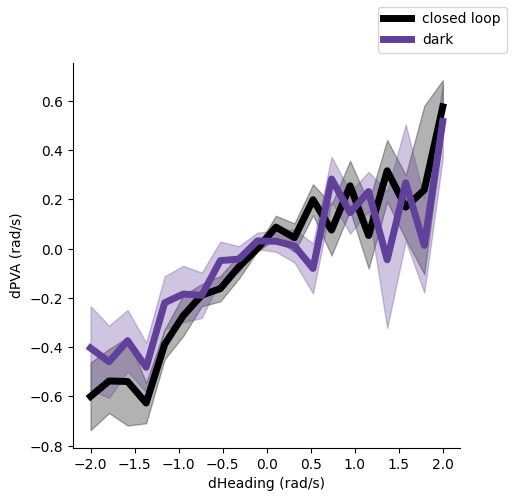

In [ ]:
fig, ax= plt.subplots(figsize=[5,5], sharey=True)
#  dphi vs dheading
cl_dat = dphi_grouped.loc[dphi_grouped['closed_loop']>0, 'dphi_dig']._values
cl_dat = np.stack(cl_dat)

mu,sem = np.nanmean(cl_dat,axis=0), sp.stats.sem(cl_dat,axis=0,nan_policy='omit')
ax.plot(dh_bins, mu, color='black', linewidth=5 , label='closed loop')
ax.fill_between(dh_bins, mu-sem, mu+sem, color='black', alpha=.3)


dark_dat = dphi_grouped.loc[dphi_grouped['closed_loop']==0, 'dphi_dig']._values
dark_dat = np.stack(dark_dat)


mu,sem = np.nanmean(dark_dat,axis=0), sp.stats.sem(dark_dat,axis=0,nan_policy='omit')
ax.plot(dh_bins, mu, color=plt.cm.Purples(.8), linewidth=5, label='dark' )
ax.fill_between(dh_bins, mu-sem, mu+sem, color=plt.cm.Purples(.8), alpha=.3)


fig.legend()
ax.set_xlabel('dHeading (rad/s)')
ax.set_ylabel('dPVA (rad/s)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.savefig(sess_manager.fig_folder / 'dphi_vs_dheading.pdf', bbox_inches='tight')

### pva mag vs dheading

In [33]:
rho_stats = nmp.stats.rho_stats(
    sess_manager,
    dh_bins,
    meta_cols=('fly_id', 'condition', 'closed_loop')
    )

In [34]:
rho_stats = rho_stats.loc[rho_stats['closed_loop']!=1] # exclude first closed loop session
rho_stats.loc[rho_stats['closed_loop']>1, 'closed_loop'] = 1 #

rho_grouped = rho_stats.groupby(['fly_id','closed_loop'])['rho_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))
rho_grouped = rho_grouped.reset_index()

/tmp/ipykernel_41423/904478122.py:4: RuntimeWarning: Mean of empty slice
  rho_grouped = rho_stats.groupby(['fly_id','closed_loop'])['rho_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))


/tmp/ipykernel_41423/3568224863.py:4: RuntimeWarning: Mean of empty slice
  mu, sem = np.nanmean(cl_dat, axis=0), sp.stats.sem(cl_dat, axis=0, nan_policy='omit')
/tmp/ipykernel_41423/3568224863.py:4: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  mu, sem = np.nanmean(cl_dat, axis=0), sp.stats.sem(cl_dat, axis=0, nan_policy='omit')
/tmp/ipykernel_41423/3568224863.py:9: RuntimeWarning: Mean of empty slice
  mu, sem = np.nanmean(dark_dat, axis=0), sp.stats.sem(dark_dat, axis=0, nan_policy='omit')
/tmp/ipykernel_41423/3568224863.py:9: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  mu, sem = np.nanmean(dark_dat, axis=0), sp.stats.sem(dark_dat, axis=0, nan_pol

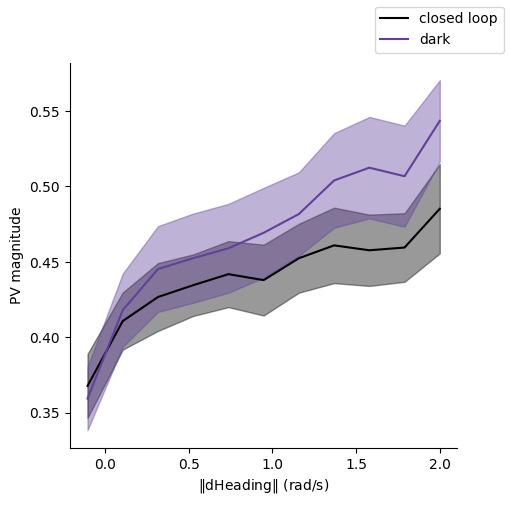

In [39]:
fig,ax = plt.subplots(sharey=True, figsize=[5,5])

cl_dat = np.stack(rho_grouped.loc[rho_grouped['closed_loop']==1,'rho_dig'])
mu, sem = np.nanmean(cl_dat, axis=0), sp.stats.sem(cl_dat, axis=0, nan_policy='omit')
ax.plot(dh_bins, mu, color='black', label='closed loop')
ax.fill_between(dh_bins, mu-sem, mu+sem, color='black', alpha=.4)

dark_dat = np.stack(rho_grouped.loc[rho_grouped['closed_loop']==0,'rho_dig'])
mu, sem = np.nanmean(dark_dat, axis=0), sp.stats.sem(dark_dat, axis=0, nan_policy='omit')
ax.plot(dh_bins, mu, color=plt.cm.Purples(.8), label='dark')
ax.fill_between(dh_bins, mu-sem, mu+sem, color=plt.cm.Purples(.8), alpha=.4)

ax.set_xlabel(r'$\|$dHeading$\|$ (rad/s)')
ax.set_ylabel('PV magnitude')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.legend()
fig.savefig(sess_manager.fig_folder / 'PVMag_vs_dheading.pdf', bbox_inches='tight')

## Bump width comparisons

Error loading 04_02_2025_fly2_control
(16, 16) (16, 16)


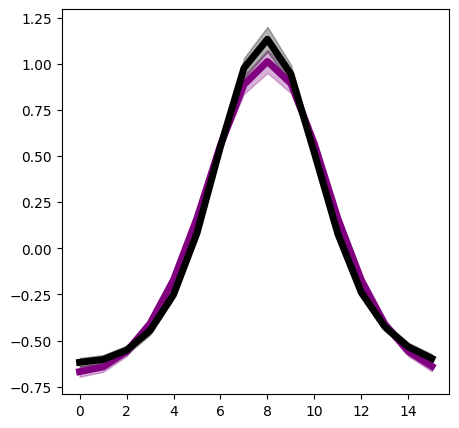

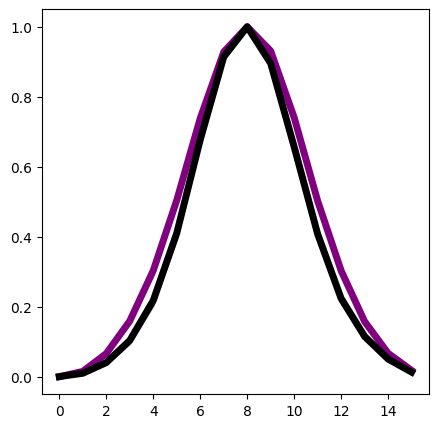

In [25]:
fig, ax = plt.subplots(figsize=[5,5])
# fly_ids = sess_df['fly_id'].unique()
dark = []
cl = []
for r, fly in enumerate(fly_ids[:]):
    try:
        dark_sess = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==0)].iloc[0]
        cl_sess = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==1)].iloc[0]

        ts = nmp.session.GetTS(load_row(dark_sess), t_sigma=.1, h_sigma=.1,zscore=True)
        # print(ts.dff.shape)
        # dff_max_aligned_dark = nmp.bump_shape.shift_by_max(ts.dff[np.newaxis, :, :], sortby_index=0)
        dff_max_aligned_dark, _, _, rho_dark, harmonic_ratio_dark = nmp.bump_shape.phase_null(ts.dff.T)
        dff_max_aligned_dark = dff_max_aligned_dark.T

        ts = nmp.session.GetTS(load_row(cl_sess), t_sigma=.1, h_sigma=.1, zscore=True)
        dff_max_aligned_cl, _, _, rho_cl, harmonic_ratio_cl = nmp.bump_shape.phase_null(ts.dff.T)
        dff_max_aligned_cl = dff_max_aligned_cl.T

        
        dark.append(dff_max_aligned_dark[:, rho_dark>.05].mean(axis=1))
        cl.append(dff_max_aligned_cl[:, rho_cl>.05].mean(axis=1))
        
    except:
        print(f'Error loading {fly}')

dark = np.stack(dark)
cl = np.stack(cl)
print(dark.shape, cl.shape)

mu, sem = np.nanmean(dark, axis=0), sp.stats.sem(dark, axis=0, nan_policy='omit')
ax.plot(mu, color='purple', linewidth=5, label='dark')
ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='purple', alpha=.3)

mu, sem = np.nanmean(cl, axis=0), sp.stats.sem(cl, axis=0, nan_policy='omit')
ax.plot(mu, color='black', linewidth=5, label='closed loop')
ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='black', alpha=.3)


fig, ax = plt.subplots(figsize=[5,5])
dark_norm = (dark - np.nanmin(dark, axis=1, keepdims=True)) / (np.nanmax(dark, axis=1, keepdims=True) - np.nanmin(dark, axis=1, keepdims=True))
cl_norm = (cl - np.nanmin(cl, axis=1, keepdims=True)) / (np.nanmax(cl, axis=1, keepdims=True) - np.nanmin(cl, axis=1, keepdims=True))
mu, sem = np.nanmean(dark_norm, axis=0), sp.stats.sem(dark_norm, axis=0, nan_policy='omit')
ax.plot(mu, color='purple', linewidth=5, label='dark')
ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='purple', alpha=.3)   
mu, sem = np.nanmean(cl_norm, axis=0), sp.stats.sem(cl_norm, axis=0, nan_policy='omit')
ax.plot(mu, color='black', linewidth=5, label='closed loop')
ax.fill_between(np.arange(mu.size), mu-sem, mu+sem, color='black', alpha=.3)

Wilcoxon test for width difference: W=4.0, p=0.000213623046875


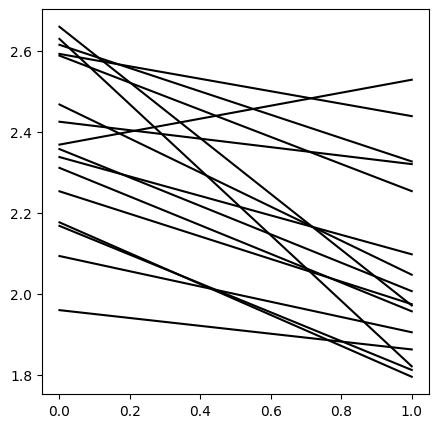

In [27]:
fwhm_dark = nmp.bump_shape.fwhm(dark, factor=16, baseline="min")
fwhm_cl = nmp.bump_shape.fwhm(cl, factor=16, baseline="min")

fig, ax = plt.subplots(figsize=[5,5])
width = np.zeros((dark.shape[0],2))
width[:,0] = fwhm_dark
width[:,1] = fwhm_cl

ax.plot([0,1], width.T, color='black', zorder=-10)
t, p = sp.stats.wilcoxon(width[:,0], width[:,1])
print(f"Wilcoxon test for width difference: W={t}, p={p}")

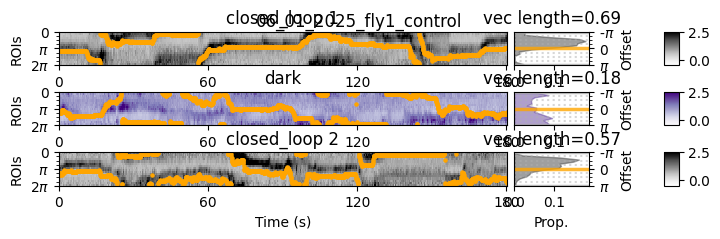

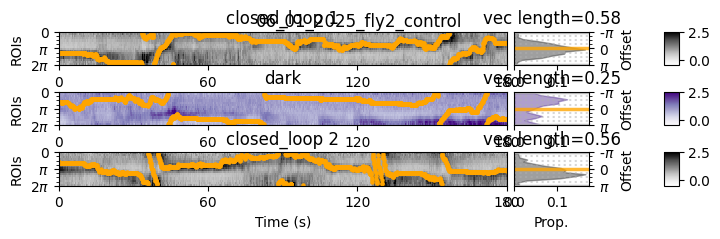

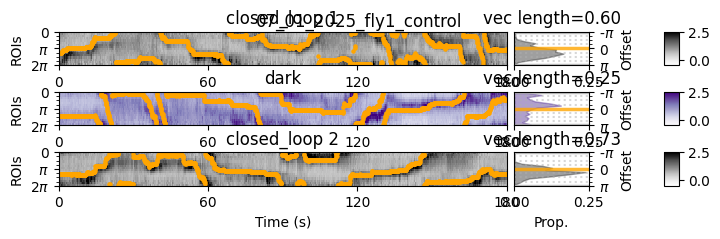

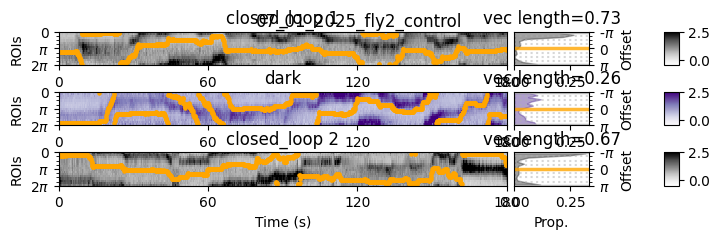

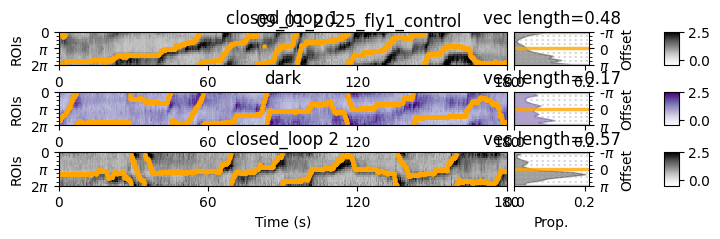

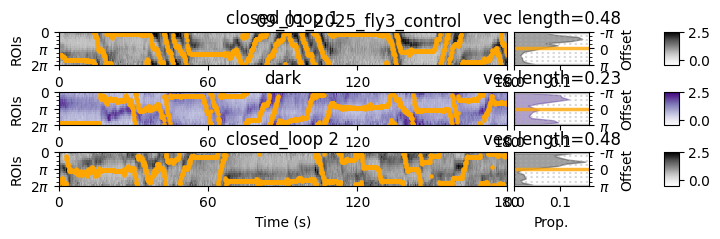

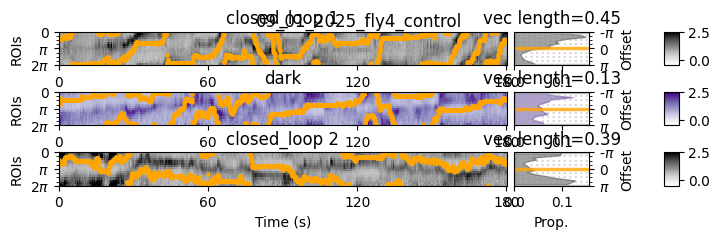

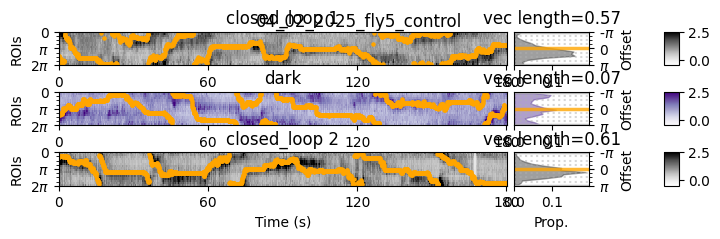

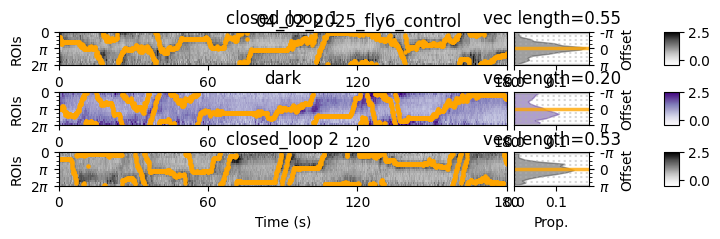

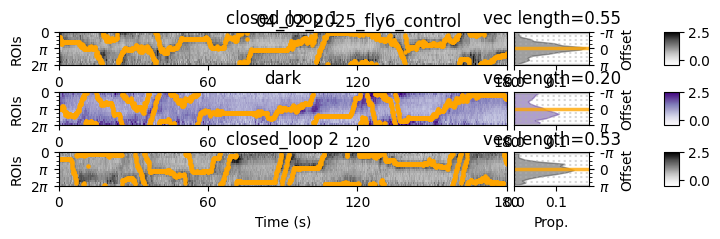

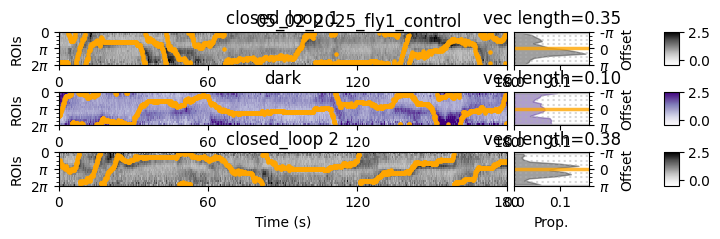

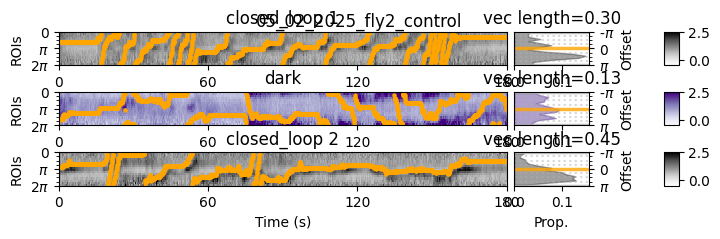

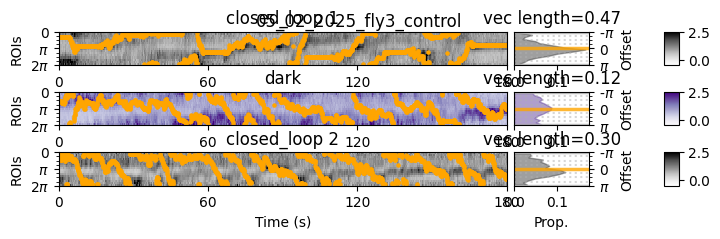

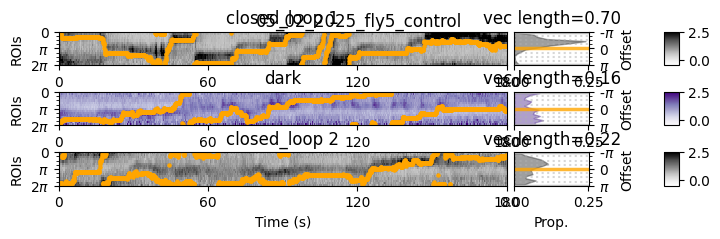

In [24]:

session_folder = figfolder / "sessions"
session_folder.mkdir(parents=True, exist_ok=True)
zscore = False

for fly in ctrl_fly_ids:
    # fly = ctrl_fly_ids[0]
    cl1 = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==1)]
    dark = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==0)]
    cl2 = sess_df.loc[(sess_df['fly_id']==fly) & (sess_df['closed_loop']==2)]

    if cl1.shape[0]>0 and dark.shape[0]>0 and cl2.shape[0]>0:
        
        ts_dict = {'fly': fly,
                    'closed_loop 1': nmp.session.GetTS(load_row(cl1.iloc[0]), zscore=zscore),
                    'dark': nmp.session.GetTS(load_row(dark.iloc[0]), zscore=zscore),
                    'closed_loop 2': nmp.session.GetTS(load_row(cl2.iloc[0]), zscore=zscore),
                    }
        
    else:
        pass


    fig, ax = nmp.epg_across_dark.plot_sess_heatmaps_w_hist(ts_dict, vmax=2.5, twindow=(0,180.1))
    fly_folder = session_folder / fly
    fly_folder.mkdir(parents=True, exist_ok=True)
    
    fig.savefig(fly_folder / "heatmaps.pdf")
